# Combo 1 — Coupling beams tie two walls (§18.10.7)

The most direct *beam + wall* interaction is a **coupling beam**: a deep beam spanning the doorway between two wall piers. Its behaviour is governed by the **aspect ratio `ln/h`**:

| `ln/h` | Required reinforcement | Clause |
|--------|------------------------|--------|
| `>= 4` | design as an ordinary SMF beam | §18.10.7.1 |
| `< 2` and high shear | **diagonal** reinforcement *mandatory* | §18.10.7.2 |
| in between | designer's choice | §18.10.7.3 |

This notebook builds a coupling beam, classifies it, sweeps the aspect ratio to map the three regimes, and computes the **diagonal shear capacity** `Vn = 2·Avd·fy·sin(α) ≤ 0.83·√f'c·Acw` (§18.10.7.4).

## Setup

In [1]:
%matplotlib inline
import sys, pathlib, warnings
warnings.simplefilter("ignore", DeprecationWarning)
_root = pathlib.Path.cwd().resolve()
while _root != _root.parent and not (_root / "design" / "__init__.py").is_file():
    _root = _root.parent
if (_root / "design").is_dir() and str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import numpy as np
import matplotlib.pyplot as plt
from design.common.materials import Concrete, Steel
from design.walls.coupling_beam import (
    CouplingBeam, coupling_beam_classification, vn_diagonal_coupling)

concrete = Concrete(fc=35.0)
steel = Steel(fy=420.0)

## A single coupling beam

A squat coupling beam over a 1.2 m doorway, 600 mm deep, 300 mm wide. `Acw = h·b` is the web area used for the shear caps.

In [2]:
cb = CouplingBeam(ln=1200, h=600, b=300, concrete=concrete, steel=steel)
Vu = 900.0   # kN of in-plane shear demand on the coupling beam
cls = cb.classify(Vu)
print(f"ln/h = {cls.ln_over_h:.2f}")
print(f"type required     = {cls.type_required}")
print(f"diagonal mandatory= {cls.diagonal_mandatory}")
for n in cls.notes:
    print("  -", n)

ln/h = 2.00
type required     = either
diagonal mandatory= False
  - Either conventional or diagonal allowed; check serviceability.


## Diagonal shear capacity (§18.10.7.4)

For the diagonally reinforced case we provide two diagonal groups at angle `α` and check the capacity against the `0.83·√f'c·Acw` ceiling.

In [3]:
Avd = 4 * np.pi * 25**2 / 4      # 4 # 25 mm bars per diagonal group (mm^2)
alpha_deg = np.degrees(np.arctan((cb.h - 100) / cb.ln))   # diagonal angle
Vn = cb.diagonal_capacity(Avd=Avd, alpha_deg=alpha_deg)
Vn_raw, Vn_cap = vn_diagonal_coupling(Avd=Avd, fy=steel.fy, alpha_deg=alpha_deg,
                                      fc=concrete.fc, Acw=cb.Acw, lam=concrete.lam)
print(f"alpha       = {alpha_deg:.1f} deg")
print(f"Vn (raw)    = {Vn_raw:.0f} kN")
print(f"Vn cap      = {Vn_cap:.0f} kN  (0.83 sqrt(fc) Acw)")
print(f"Vn governing= {Vn:.0f} kN   vs demand Vu = {Vu:.0f} kN -> "
      f"{'OK' if Vn >= Vu else 'NG'}")

alpha       = 22.6 deg
Vn (raw)    = 634 kN
Vn cap      = 884 kN  (0.83 sqrt(fc) Acw)
Vn governing= 634 kN   vs demand Vu = 900 kN -> NG


## Sweep the aspect ratio — map the three regimes

We hold `h = 600 mm` and vary the clear span `ln` from very squat to slender, classifying each. The shaded bands show where the code mandates diagonal reinforcement, leaves it to the designer, or treats the member as an ordinary beam.

In [4]:
lns = np.linspace(800, 3200, 25)
h = 600.0
ratios, kinds = [], []
for ln in lns:
    c = coupling_beam_classification(ln=ln, h=h, Vu=900.0,
                                     Acw=h*300, fc=concrete.fc)
    ratios.append(c.ln_over_h)
    kinds.append(c.type_required)
print("regimes found:", sorted(set(kinds)))

regimes found: ['conventional', 'diagonal', 'either']


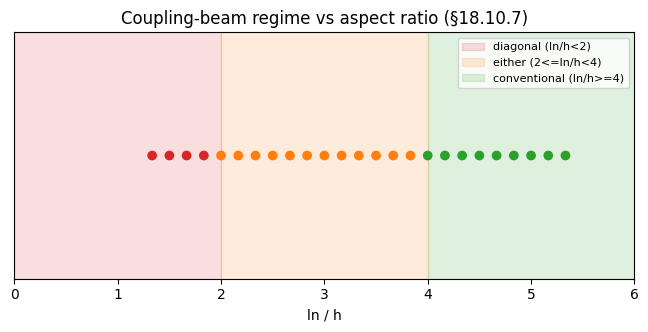

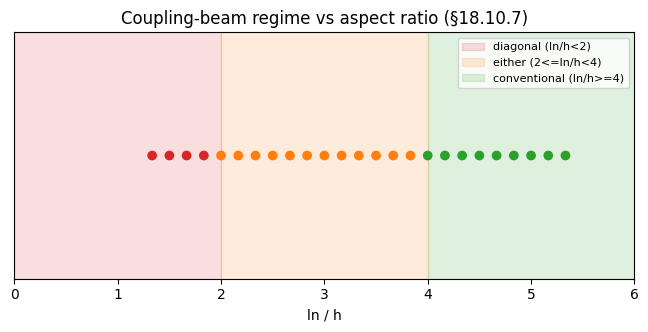

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.axvspan(0, 2, color="tab:red",   alpha=0.15, label="diagonal (ln/h<2)")
ax.axvspan(2, 4, color="tab:orange",alpha=0.15, label="either (2<=ln/h<4)")
ax.axvspan(4, 6, color="tab:green", alpha=0.15, label="conventional (ln/h>=4)")
colors = {"diagonal":"tab:red","either":"tab:orange","conventional":"tab:green"}
ax.scatter(ratios, np.zeros_like(ratios), c=[colors[k] for k in kinds], zorder=3)
ax.set_xlim(0, 6); ax.set_yticks([])
ax.set_xlabel("ln / h"); ax.set_title("Coupling-beam regime vs aspect ratio (§18.10.7)")
ax.legend(loc="upper right", fontsize=8)
fig

---
**Takeaway.** The same `CouplingBeam` object answers *both* the classification question (which reinforcement scheme the code requires) and the capacity question (`Vn` of the diagonal layout) — the bridge between the beam and wall worlds.